# 10 — Attention : quelles coupes sont ignorées

Les 24 coupes NPZ sont un **linspace dans la bande 20–80 %**. Chaque tête (12 findings) fait un softmax sur les 72 tokens (3 plans × 24). Si les indices de bord n’ont jamais de masse, on peut :

1. **les retirer** du tenseur (`x[:, :, lo:hi+1]`, pas de reconversion) ;
2. **resserrer la bande** à la conversion (mêmes 24 coupes, plus denses au centre utile).

Les archis sont figées : le script accroche `attn_score` et rejoue le masque / softmax.

Défaut : **v11 full-train** (`v11_crop130v1`, public LB 0,914) — c’est le signal le plus fiable pour changer le sampling. Le subset v8bis convnext-small s’est effondré (proba std ≈ 0) : son attention n’est pas lisible.

```text
python -X utf8 -m src.infer.inspect_attention --config configs/kneenet_v11_crop130.yaml
```

In [1]:
from __future__ import annotations

import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.infer.inspect_attention import load_config, run

CONFIG = ROOT / "configs" / "kneenet_v11_crop130.yaml"
# CONFIG = ROOT / "configs" / "kneenet_v8_crop130_subset.yaml"
FORCE = False  # True = relancer le forward même si summary.json existe
SPLIT = "val"  # "val" | "gold" (58, plus rapide)
MAX_STUDIES = None  # ex. 80 pour un aperçu

cfg = load_config(str(CONFIG))
OUT = ROOT / "checkpoints" / cfg["run_name"] / "attention_inspect"
CKPT = ROOT / "checkpoints" / cfg["run_name"] / "best.pt"
print("config", CONFIG.name)
print("ckpt  ", CKPT, "exists", CKPT.exists())
print("out   ", OUT)

config kneenet_v11_crop130.yaml
ckpt   c:\Users\sulta\Documents\RSNA-comp\checkpoints\v11_crop130v1\best.pt exists True
out    c:\Users\sulta\Documents\RSNA-comp\checkpoints\v11_crop130v1\attention_inspect


In [2]:
import torch

summary_path = OUT / "summary.json"
if summary_path.exists() and not FORCE:
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    print("chargé", summary_path)
else:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    summary = run(
        cfg, CKPT, SPLIT, OUT, device,
        batch_size=int(cfg.get("batch_size") or 4),
        num_workers=2,
        max_studies=MAX_STUDIES,
        n_examples=4,
    )

print(
    f"{summary['model']}  epoch {summary['epoch']}  "
    f"val AUC {summary['val_macro_auc']}  "
    f"{summary['split']} n={summary['n_studies']}"
)

chargé c:\Users\sulta\Documents\RSNA-comp\checkpoints\v11_crop130v1\attention_inspect\summary.json
kneenet_v11  epoch 11  val AUC 0.8614152836111016  gold n=2


In [3]:
tbl = pd.read_csv(OUT / "slice_attention.csv")
sug = summary["suggested"]
dead = summary["dead_idx"]
tbl["flag"] = ""
tbl.loc[tbl.slice.isin(sug["drop_idx"]), "flag"] = "bord 90%"
tbl.loc[tbl.slice.isin(dead), "flag"] = "morte"
display(
    tbl.style.format({
        "depth_pct": "{:.0f}%",
        "mass": "{:.2%}",
        "pct_top5_any": "{:.1%}",
        "mass_sag": "{:.4f}",
        "mass_cor": "{:.4f}",
        "mass_axi": "{:.4f}",
    })
)
print(
    f"90 % de la masse : coupes {sug['keep_lo']}–{sug['keep_hi']} "
    f"({sug['n_keep']}/24) → bande "
    f"{100*sug['band_lo']:.0f}–{100*sug['band_hi']:.0f} % "
    f"(masse {100*sug['kept_mass']:.1f} %)"
)
print("coupes mortes :", dead if dead else "(aucune au sens strict)")
print(
    f"sans reconvertir : x[:, :, {sug['keep_lo']}:{sug['keep_hi']+1}]  "
    f"(D={sug['n_keep']})"
)
print(
    f"reconvertir : BAND=({sug['band_lo']:.2f}, {sug['band_hi']:.2f}) "
    f"et garder 24 coupes"
)

,slice,depth_pct,mass,pct_top5_any,mass_sag,mass_cor,mass_axi,flag
0,0,20%,6.08%,50.0%,0.0153,0.0366,0.0089,
1,1,23%,6.39%,83.3%,0.0250,0.0241,0.0147,
2,2,25%,5.54%,66.7%,0.0156,0.0310,0.0087,
3,3,28%,4.89%,83.3%,0.0151,0.0266,0.0071,
4,4,30%,6.71%,83.3%,0.0236,0.0353,0.0083,
5,5,33%,4.38%,66.7%,0.0156,0.0191,0.0091,
6,6,36%,3.45%,50.0%,0.0111,0.0160,0.0075,
7,7,38%,3.12%,50.0%,0.0127,0.0130,0.0056,
8,8,41%,3.16%,16.7%,0.0120,0.0115,0.0081,
9,9,44%,3.67%,50.0%,0.0150,0.0140,0.0077,


90 % de la masse : coupes 0–21 (22/24) → bande 20–75 % (masse 93.1 %)
coupes mortes : (aucune au sens strict)
sans reconvertir : x[:, :, 0:22]  (D=22)
reconvertir : BAND=(0.20, 0.75) et garder 24 coupes


attn_profile.png


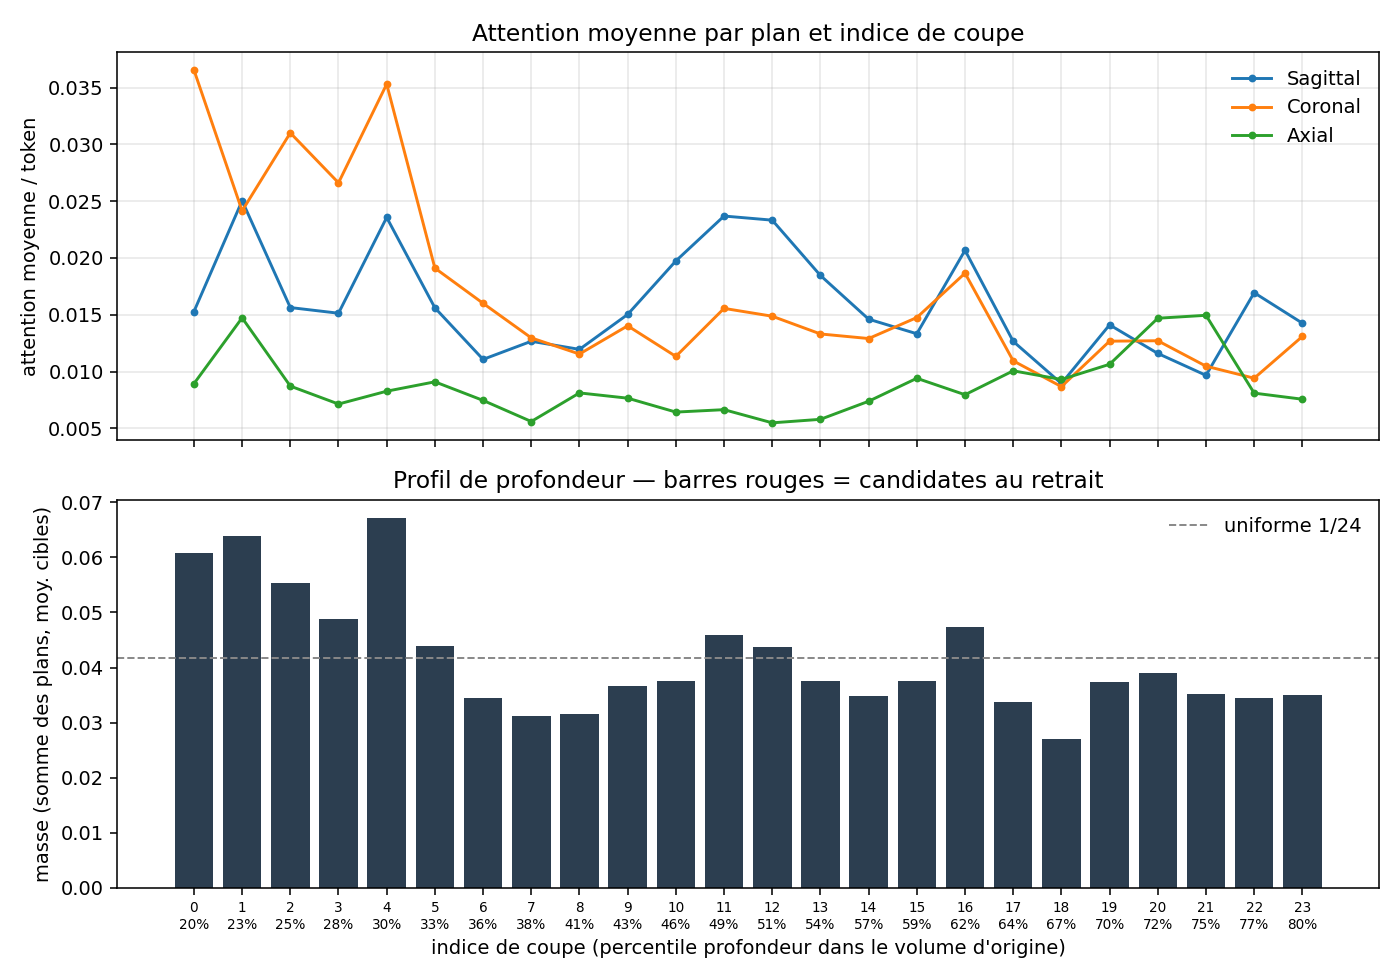

attn_heatmap_planes.png


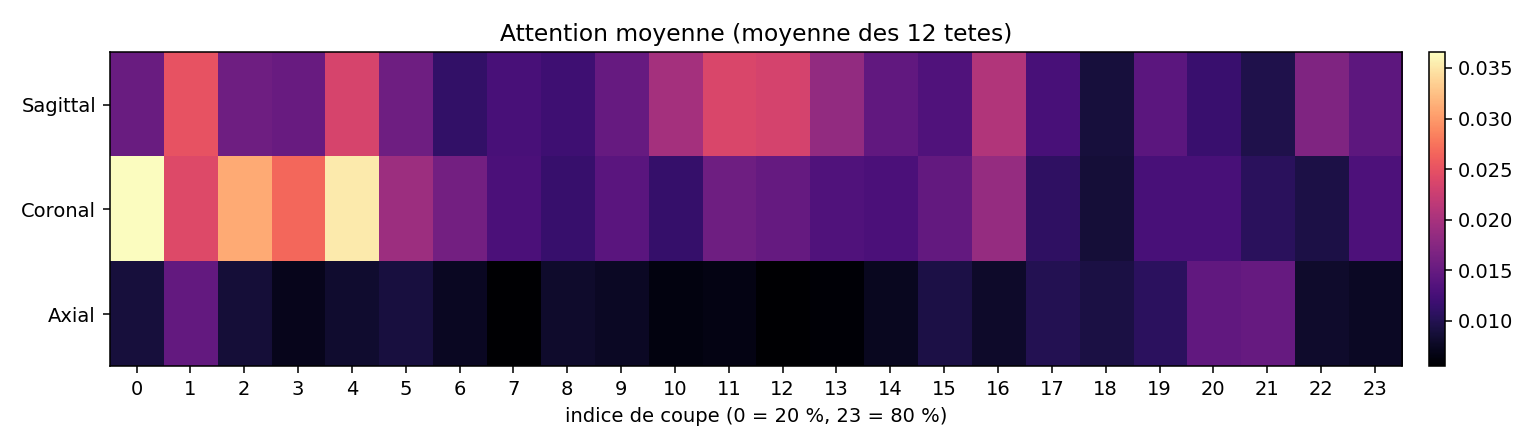

attn_heatmap_targets.png


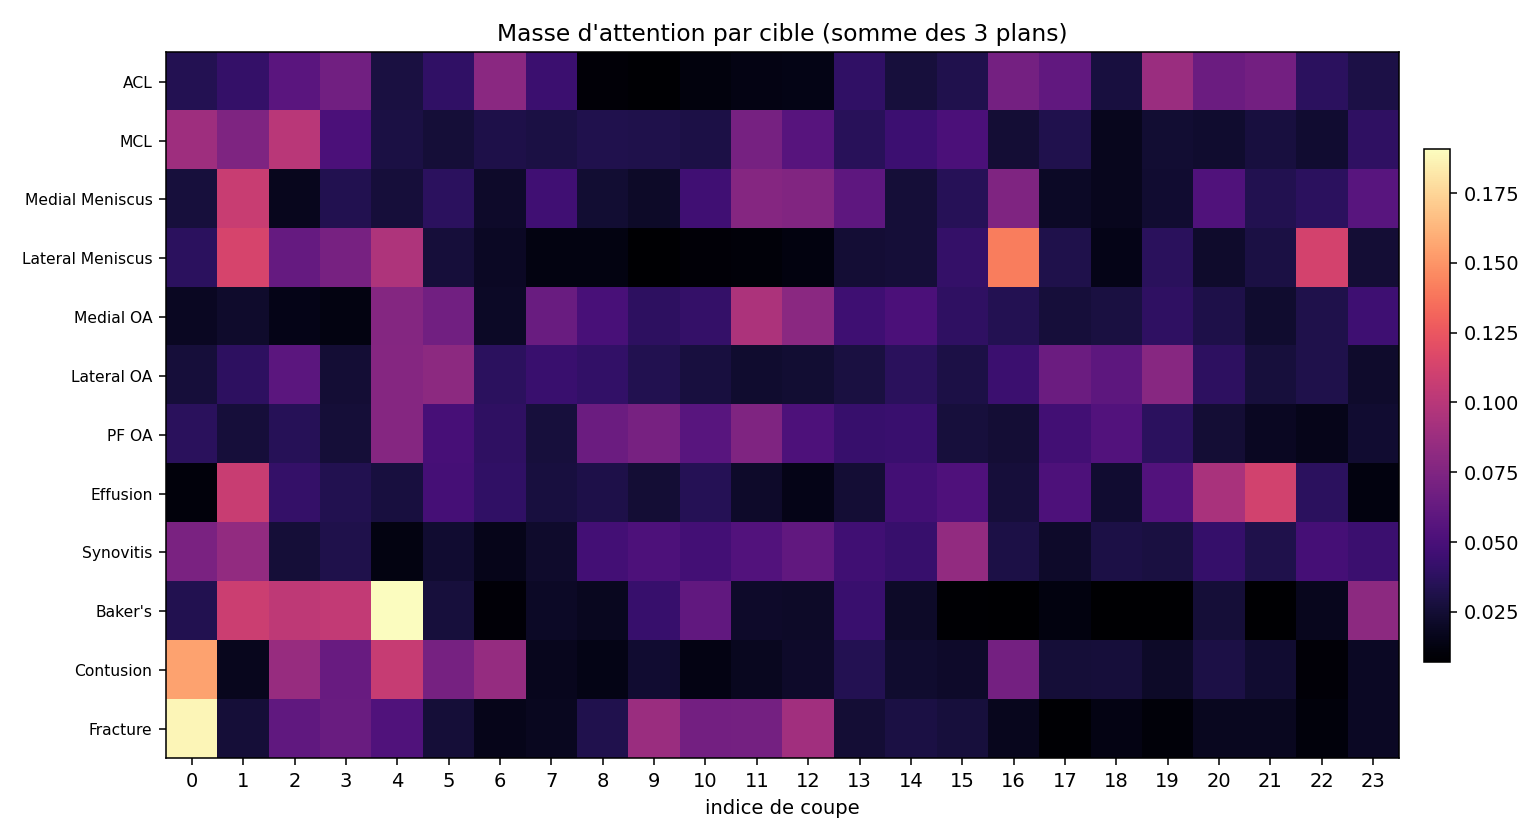

In [4]:
for name in ("attn_profile.png", "attn_heatmap_planes.png", "attn_heatmap_targets.png"):
    p = OUT / name
    print(p.name)
    display(Image(filename=str(p)))

3 mosaics
ex0_ACL.png


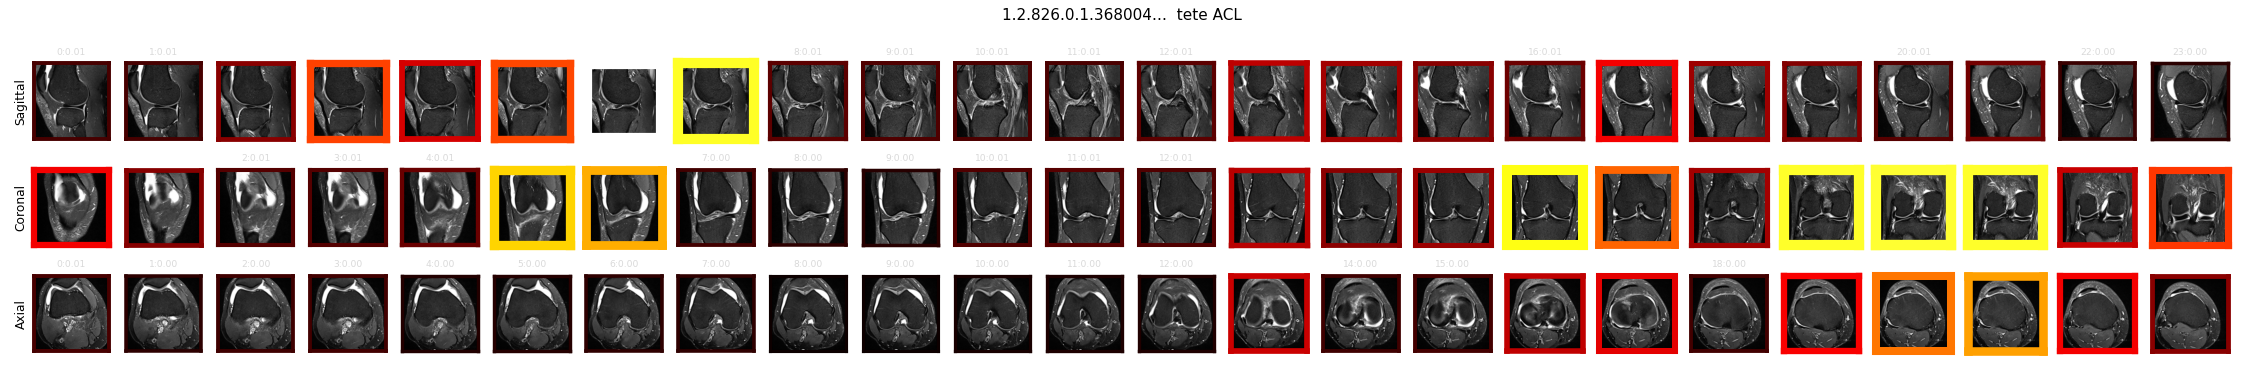

ex0_Bakers.png


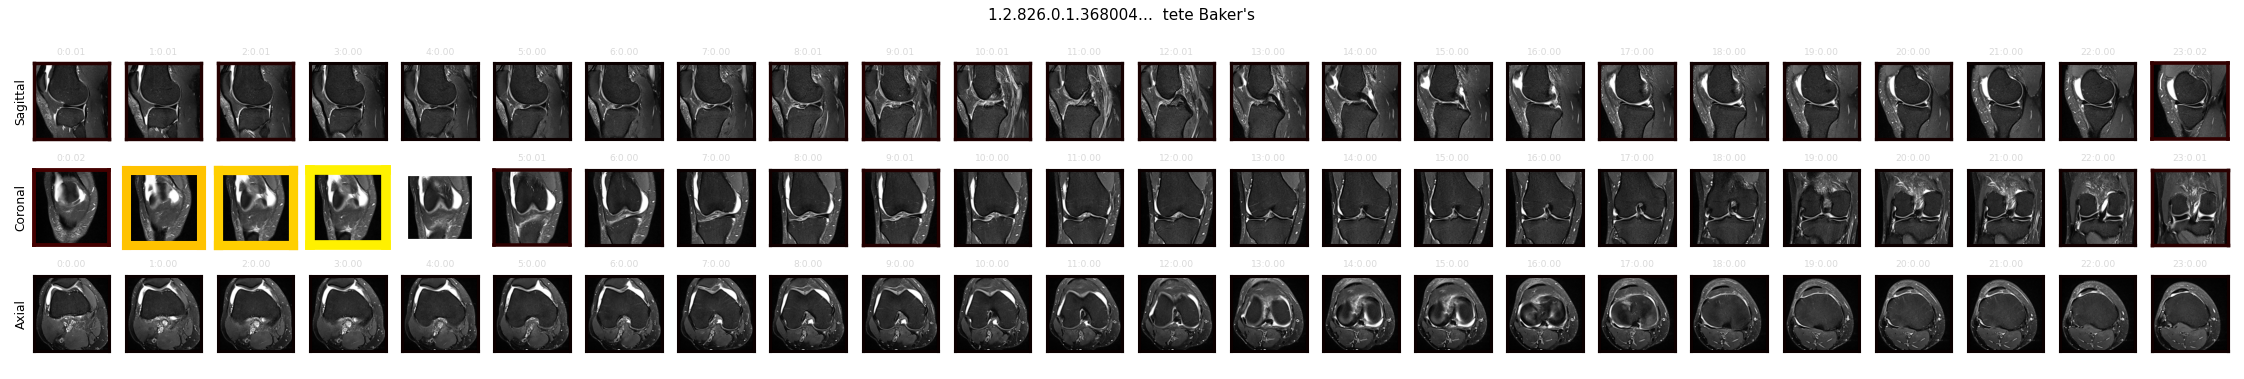

ex0_Effusion.png


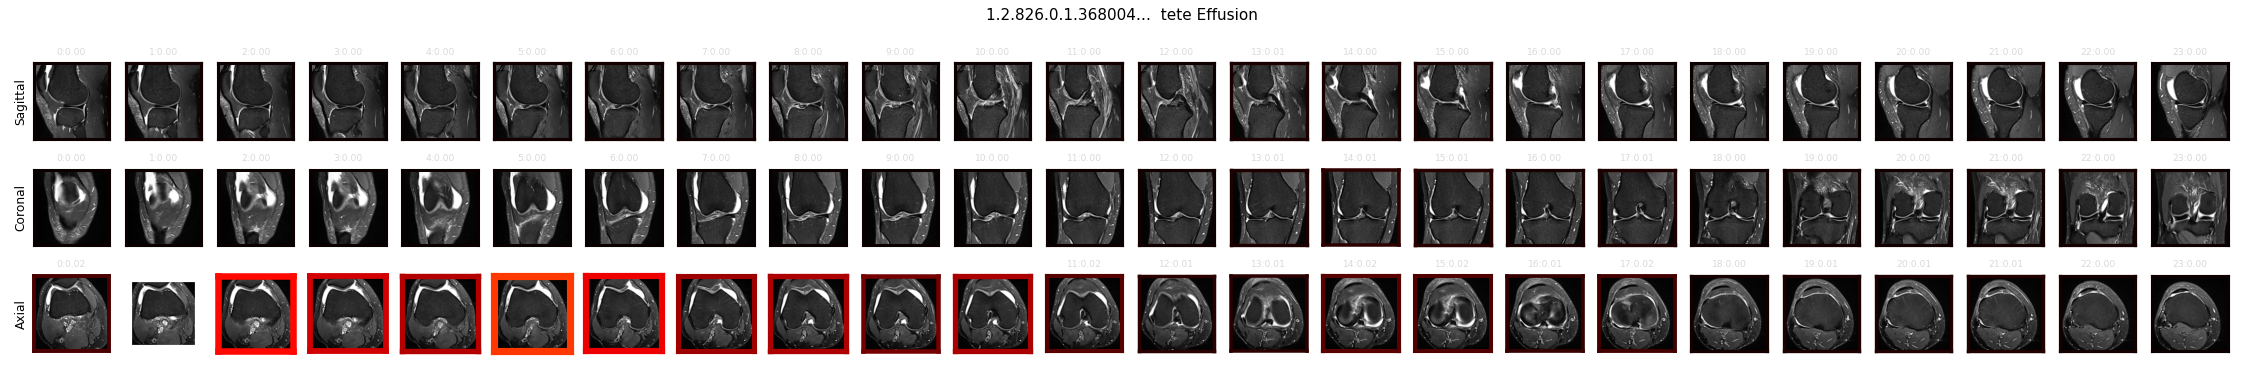

In [5]:
ex_dir = OUT / "examples"
files = sorted(ex_dir.glob("*.png")) if ex_dir.exists() else []
print(len(files), "mosaics")
for p in files[:6]:
    print(p.name)
    display(Image(filename=str(p)))